> **Frozen evidence notebook.** Outputs were produced on the earlier 1,256-row dataset, before the 21 grey-iron rows with assumed elongation were held out of fitting. It documents why that exclusion was made. Do not re-run: the processed data it reads has since changed. (The main pipeline is notebooks 02 to 08.)

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
sns.set_theme(style="whitegrid")

CORE = ["tensile_strength_MPa", "yield_strength_MPa", "elongation_pct",
        "youngs_modulus_GPa", "density_g_cm3"]

X = pd.read_csv("../data/processed/materials_scaled.csv", index_col=0)
meta = pd.read_csv("../data/processed/materials_features.csv").set_index("label").loc[X.index]
assert (X.index == meta.index).all()
print(X.shape, meta.shape)

(1256, 5) (1256, 21)


In [2]:
rows = []
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, km.labels_),
        "davies_bouldin": davies_bouldin_score(X, km.labels_),
        "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
    })
sweep = pd.DataFrame(rows).set_index("k")
display(sweep.round(3))

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,3285.094,0.551,0.795,1143.228
3,2165.629,0.404,0.879,1190.256
4,1716.426,0.422,0.800,1109.591
5,1320.840,0.437,0.807,1174.236
6,1155.992,0.376,0.903,1108.141
7,992.483,0.358,0.956,1109.059
8,866.860,0.365,0.890,1113.312
9,755.692,0.392,0.837,1139.512
10,673.091,0.381,0.861,1153.254


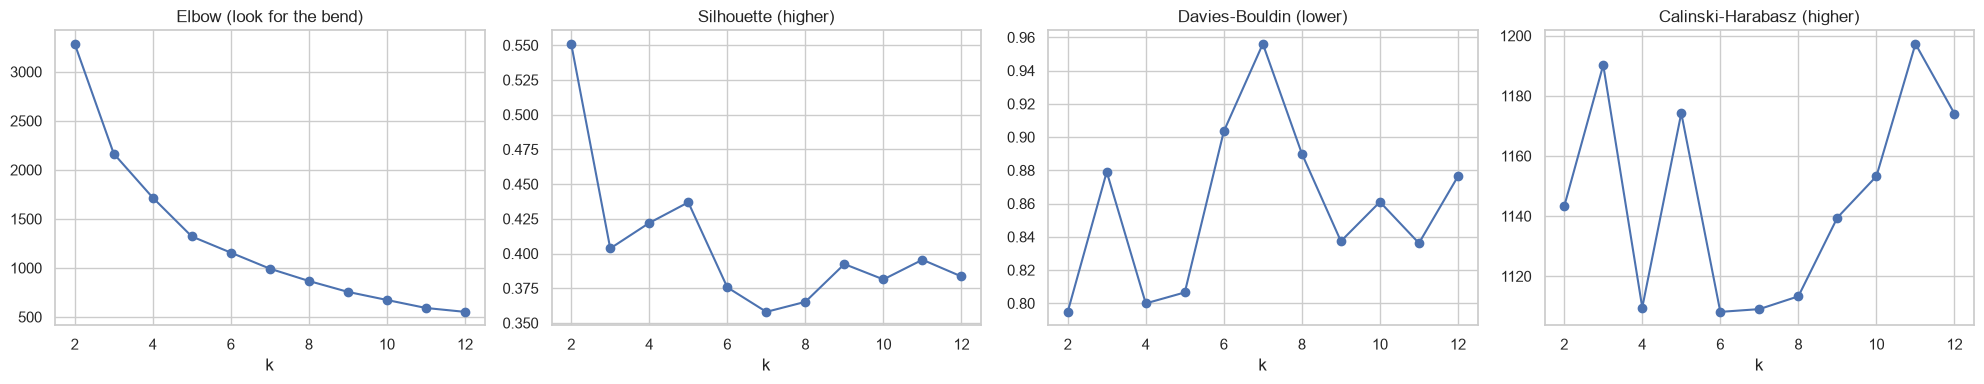

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
titles = {"inertia": "Elbow (look for the bend)", "silhouette": "Silhouette (higher)",
          "davies_bouldin": "Davies-Bouldin (lower)", "calinski_harabasz": "Calinski-Harabasz (higher)"}
for ax, (col, title) in zip(axes, titles.items()):
    ax.plot(sweep.index, sweep[col], marker="o"); ax.set_title(title); ax.set_xlabel("k")
plt.tight_layout(); plt.savefig("../figures/05_choose_k.png", dpi=150); plt.show()

In [4]:
CANDIDATES = [3, 5, 6]
for K in CANDIDATES:
    km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X)
    meta[f"km{K}"] = km.labels_
    print(f"\n===== K = {K}: family (rows) vs cluster (columns) =====")
    print(pd.crosstab(meta["family"], meta[f"km{K}"]))


===== K = 3: family (rows) vs cluster (columns) =====
km3                0    1    2
family                        
Aluminium        197    0    0
Cast iron         23   23   16
Copper alloy       4    5  157
Magnesium         30    0    0
Stainless steel    0   40   77
Steel              0  439  245

===== K = 5: family (rows) vs cluster (columns) =====
km5                0    1    2   3    4
family                                 
Aluminium          0    0  187  10    0
Cast iron          2   18    0  23   19
Copper alloy     134    4    0   5   23
Magnesium          0    0   29   1    0
Stainless steel    0   31    0   0   86
Steel              3  278    0   0  403

===== K = 6: family (rows) vs cluster (columns) =====
km6               0    1    2    3    4    5
family                                      
Aluminium        10    0    0  187    0    0
Cast iron        23    8   10    0    3   18
Copper alloy      5    6    0    0  142   13
Magnesium         1    0    0   29    0   

In [5]:
PROFILE = CORE + ["specific_strength"]
for K in CANDIDATES:
    prof = meta.groupby(f"km{K}")[PROFILE].median().round(1)
    prof["n"] = meta[f"km{K}"].value_counts().sort_index()
    print(f"\n===== K = {K}: median properties per cluster =====")
    display(prof)


===== K = 3: median properties per cluster =====


,tensile_strength_MPa,yield_strength_MPa,elongation_pct,youngs_modulus_GPa,density_g_cm3,specific_strength,n
km3,,,,,,,
0,241.0,172.0,10.0,73.0,2.7,88.0,254
1,800.0,560.0,12.0,206.0,7.9,101.8,507
2,455.0,245.0,25.0,206.0,7.9,57.3,495



===== K = 5: median properties per cluster =====


,tensile_strength_MPa,yield_strength_MPa,elongation_pct,youngs_modulus_GPa,density_g_cm3,specific_strength,n
km5,,,,,,,
0,310.0,138.0,35.0,105.0,8.8,35.9,139
1,929.0,685.0,11.0,206.0,7.9,118.2,331
2,241.0,172.0,11.0,73.0,2.7,97.0,216
3,241.0,172.0,0.5,91.0,7.2,34.9,39
4,540.0,315.0,20.0,206.0,7.9,68.7,531



===== K = 6: median properties per cluster =====


,tensile_strength_MPa,yield_strength_MPa,elongation_pct,youngs_modulus_GPa,density_g_cm3,specific_strength,n
km6,,,,,,,
0,241.0,172.0,0.5,91.0,7.2,34.9,39
1,483.0,262.0,25.0,206.0,7.9,61.1,297
2,1028.5,800.0,10.0,206.0,7.9,130.9,216
3,241.0,172.0,11.0,73.0,2.7,97.0,216
4,317.0,138.0,35.0,105.0,8.8,36.5,145
5,670.0,410.0,14.0,206.0,7.9,85.2,343


In [6]:
meta["quality"] = np.select(
    [meta["elongation_assumed"].astype(bool), meta["elongation_imputed"].astype(bool)],
    ["assumed 0.5", "KNN-imputed"], default="measured")

print(pd.crosstab(meta["km5"], meta["quality"]))

brittle = meta[meta["km5"] == 3]
print("\nNon-cast-iron members of cluster 3:")
display(brittle.loc[brittle["family"] != "Cast iron",
        ["family", "tensile_strength_MPa", "elongation_pct", "density_g_cm3", "quality"]])

quality  KNN-imputed  assumed 0.5  measured
km5                                        
0                 10            0       129
1                 59            0       272
2                 18            0       198
3                  2           21        16
4                 42            0       489

Non-cast-iron members of cluster 3:


,family,tensile_strength_MPa,elongation_pct,density_g_cm3,quality
label,,,,,
Tin Bronze C91000 | n/a,Copper alloy,221.0,2.0,8.80,measured
Tin Bronze C91100 | n/a,Copper alloy,241.0,2.0,8.80,measured
Tin Bronze C91300 | n/a,Copper alloy,241.0,0.5,8.80,measured
Leaded Tin Bronze C92800 | n/a,Copper alloy,276.0,1.0,8.80,measured
Special Alloy C99300 | n/a,Copper alloy,655.0,2.0,8.50,measured
Aluminum Alloy 208.0 | Cast (F),Aluminium,131.0,1.5,2.70,measured
Aluminum Alloy 242.0 | Cast (T77),Aluminium,165.0,1.0,2.70,measured
Aluminum Alloy 319.0 | Cast (F),Aluminium,159.0,1.5,2.70,measured
Aluminum Alloy 319.0 | Cast (T6),Aluminium,214.0,1.5,2.70,measured


In [7]:
keep = ~meta["elongation_assumed"].astype(bool).values
Xk = X[keep]
tmp = meta[keep].copy()
tmp["km5_noassumed"] = KMeans(n_clusters=5, n_init=20, random_state=42).fit(Xk).labels_

print(pd.crosstab(tmp["km5"], tmp["km5_noassumed"]))
print("\nARI vs original K=5 on the same rows:", round(adjusted_rand_score(tmp["km5"], tmp["km5_noassumed"]), 3))

prof = tmp.groupby("km5_noassumed")[CORE].median().round(1)
prof["n"] = tmp["km5_noassumed"].value_counts().sort_index()
display(prof)

km5_noassumed    0    1    2    3    4
km5                                   
0              139    0    0    0    0
1                0  328    0    3    0
2                0    0  106    0  110
3                0    1    0    0   17
4                0    0    0  531    0

ARI vs original K=5 on the same rows: 0.948


,tensile_strength_MPa,yield_strength_MPa,elongation_pct,youngs_modulus_GPa,density_g_cm3,n
km5_noassumed,,,,,,
0,310.0,138.0,35.0,105.0,8.8,139
1,930.0,685.0,11.0,206.0,7.9,329
2,327.5,248.0,12.0,73.0,2.7,106
3,540.0,315.0,20.0,206.0,7.9,534
4,186.0,131.0,7.0,73.0,2.7,127
